In [4]:
!pip install pytsg

In [69]:
# ============================================================
# SPECTRAL DATA PREPARATION FOR PCA + CLUSTERING
#
# SWIR and TIR processed separately
#
# IMPORTANT:
# - Every valid spectral observation remains a row.
# - NO spectral averaging by depth bin.
# - NO MiniBatchKMeans before PCA.
# - Depth bins are metadata only.
# - hole_id is retained for later hole-level analysis.
# ============================================================


from pathlib import Path

import numpy as np
import pandas as pd

from pytsg.parse_tsg import read_tsg_bip_pair


# ============================================================
# 1. SETTINGS
# ============================================================

RAW_DIR = Path(
    "/Users/yeshwanth_g/Desktop/VScode/"
    "gswa-hylogger-data-crunch/data/downloads/raw"
)

# ------------------------------------------------------------
# Depth bin size
#
# This is ONLY used to label observations.
# We DO NOT average or aggregate spectra using these bins.
# ------------------------------------------------------------

DEPTH_BIN_M = 1.0

# ------------------------------------------------------------
# Random state reserved for later PCA/clustering
# ------------------------------------------------------------

RANDOM_STATE = 42


# ============================================================
# 2. CHECK RAW DIRECTORY
# ============================================================

print("=" * 90)
print("RAW DATA DIRECTORY")
print("=" * 90)

print(RAW_DIR.resolve())

if not RAW_DIR.exists():

    raise FileNotFoundError(
        f"Raw directory does not exist:\n{RAW_DIR}"
    )


# ============================================================
# 3. FIND FILE INSIDE HOLE DIRECTORY
# ============================================================

def find_file_by_suffix(hole_dir, filename):

    """
    Find a file inside a hole directory.

    Handles:
    1. Normal extraction
    2. ZIP extraction cases where Windows-style
       paths may appear inside filenames.
    """

    matches = []

    for p in hole_dir.rglob("*"):

        if not p.is_file():
            continue

        # Normal case
        if p.name == filename:

            matches.append(p)

        # ZIP extraction case
        elif p.name.endswith(filename):

            matches.append(p)


    if len(matches) == 0:

        raise FileNotFoundError(
            f"Could not find '{filename}' inside:\n"
            f"{hole_dir}"
        )


    if len(matches) > 1:

        print(
            f"WARNING: Multiple files found for "
            f"{filename}"
        )

        for m in matches:

            print("   ", m)


    return matches[0]


# ============================================================
# 4. FIND SWIR + TIR FILES
# ============================================================

def find_hole_files(
    hole_id,
    hole_dir
):

    # --------------------------------------------------------
    # SWIR / NIR
    # --------------------------------------------------------

    swir_tsg = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg.tsg"
    )

    swir_bip = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg.bip"
    )


    # --------------------------------------------------------
    # TIR
    # --------------------------------------------------------

    tir_tsg = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg_tir.tsg"
    )

    tir_bip = find_file_by_suffix(
        hole_dir,
        f"{hole_id}_tsg_tir.bip"
    )


    return {

        "swir_tsg": swir_tsg,

        "swir_bip": swir_bip,

        "tir_tsg": tir_tsg,

        "tir_bip": tir_bip

    }


# ============================================================
# 5. GET ALL HOLE DIRECTORIES
# ============================================================

hole_directories = sorted(

    [

        p

        for p in RAW_DIR.iterdir()

        if p.is_dir()

    ]

)


if len(hole_directories) == 0:

    raise FileNotFoundError(
        f"No hole directories found inside:\n"
        f"{RAW_DIR}"
    )


print("\nNumber of hole directories:")
print(len(hole_directories))


print("\nHole directories:")

for p in hole_directories:

    print(" -", p.name)


# ============================================================
# 6. STORAGE
# ============================================================

# ------------------------------------------------------------
# SWIR
# ------------------------------------------------------------

all_swir_spectra = []

all_swir_metadata = []


# ------------------------------------------------------------
# TIR
# ------------------------------------------------------------

all_tir_spectra = []

all_tir_metadata = []


# ------------------------------------------------------------
# Wavelength references
# ------------------------------------------------------------

swir_wavelength_reference = None

tir_wavelength_reference = None


# ============================================================
# 7. PREPARE ONE SENSOR
# ============================================================

def prepare_sensor_data(
    sensor_object,
    hole_id,
    sensor_name
):

    print("\n")
    print("=" * 90)
    print(f"PREPARING {sensor_name}")
    print(f"HOLE: {hole_id}")
    print("=" * 90)


    # ========================================================
    # 7.1 EXTRACT SPECTRA
    # ========================================================

    spectra = np.asarray(

        sensor_object.spectra,

        dtype=np.float64

    )


    # ========================================================
    # 7.2 EXTRACT WAVELENGTHS
    # ========================================================

    wavelengths = np.asarray(

        sensor_object.wavelength,

        dtype=np.float64

    )


    # ========================================================
    # 7.3 EXTRACT SAMPLE HEADERS
    # ========================================================

    sample_headers = (

        sensor_object
        .sampleheaders
        .copy()

    )


    # ========================================================
    # 7.4 EXTRACT SCALARS
    # ========================================================

    scalars = (

        sensor_object
        .scalars
        .copy()

    )


    # ========================================================
    # 7.5 PRINT RAW INFORMATION
    # ========================================================

    print(
        "Spectra shape:",
        spectra.shape
    )

    print(
        "Wavelength count:",
        len(wavelengths)
    )

    print(
        "Wavelength range:",
        wavelengths.min(),
        "to",
        wavelengths.max()
    )

    print(
        "Sample headers shape:",
        sample_headers.shape
    )

    print(
        "Scalars shape:",
        scalars.shape
    )


    # ========================================================
    # 7.6 VERIFY ROW ALIGNMENT
    # ========================================================

    if not (

        len(spectra)

        == len(sample_headers)

        == len(scalars)

    ):

        raise ValueError(

            f"Row alignment problem in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.7 VERIFY WAVELENGTH DIMENSION
    # ========================================================

    if spectra.shape[1] != len(wavelengths):

        raise ValueError(

            f"Wavelength alignment problem in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.8 GET ACTUAL DEPTH
    # ========================================================

    if "Depth (m)" not in scalars.columns:

        raise ValueError(

            f"'Depth (m)' was not found in "
            f"{sensor_name} scalars for {hole_id}"

        )


    depth = pd.to_numeric(

        scalars["Depth (m)"],

        errors="coerce"

    )


    # ========================================================
    # 7.9 CREATE METADATA
    # ========================================================

    metadata = sample_headers.copy()


    metadata["hole_id"] = hole_id


    metadata["depth_m"] = (
        depth.to_numpy()
    )


    metadata["original_row"] = np.arange(

        len(metadata)

    )


    # ========================================================
    # 7.10 CREATE DEPTH BIN LABEL
    #
    # IMPORTANT:
    # This DOES NOT modify the spectrum.
    #
    # It simply tells us which depth interval
    # the observation belongs to.
    # ========================================================

    metadata["depth_bin"] = (

        np.floor(

            metadata["depth_m"]
            / DEPTH_BIN_M

        )

        * DEPTH_BIN_M

    )


    metadata["depth_bin"] = (

        metadata["depth_bin"]
        .round(6)

    )


    # ========================================================
    # 7.11 SPECTRAL QC
    # ========================================================

    finite_spectra = np.isfinite(

        spectra

    ).all(axis=1)


    spectral_variance = np.nanvar(

        spectra,

        axis=1

    )


    non_constant_spectra = (

        spectral_variance
        > 1e-12

    )


    valid_depth = (

        metadata["depth_m"]
        .notna()
        .to_numpy()

    )


    valid_mask = (

        finite_spectra

        &

        non_constant_spectra

        &

        valid_depth

    )


    # ========================================================
    # 7.12 QC REPORT
    # ========================================================

    print(
        "\nTotal raw observations:",
        len(spectra)
    )

    print(
        "Valid observations:",
        valid_mask.sum()
    )

    print(
        "Removed observations:",
        (~valid_mask).sum()
    )


    # ========================================================
    # 7.13 APPLY QC
    # ========================================================

    spectra_clean = (

        spectra[
            valid_mask
        ]

    )


    metadata_clean = (

        metadata
        .loc[valid_mask]
        .reset_index(drop=True)

    )


    # ========================================================
    # 7.14 SORT BY DEPTH
    #
    # IMPORTANT:
    # Sorting changes row order only.
    # It does NOT change spectral values.
    # ========================================================

    order = np.argsort(

        metadata_clean[
            "depth_m"
        ].to_numpy()

    )


    spectra_clean = (

        spectra_clean[
            order
        ]

    )


    metadata_clean = (

        metadata_clean
        .iloc[order]
        .reset_index(drop=True)

    )


    # ========================================================
    # 7.15 VERIFY FINAL ALIGNMENT
    # ========================================================

    if len(spectra_clean) != len(metadata_clean):

        raise ValueError(

            f"Spectral/metadata alignment "
            f"problem after QC in "
            f"{sensor_name} / {hole_id}"

        )


    if spectra_clean.shape[1] != len(wavelengths):

        raise ValueError(

            f"Spectrum/wavelength alignment "
            f"problem after QC in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.16 FINAL QC
    # ========================================================

    if not np.isfinite(

        spectra_clean

    ).all():

        raise ValueError(

            f"Non-finite values remain in "
            f"{sensor_name} / {hole_id}"

        )


    if not metadata_clean["depth_m"].notna().all():

        raise ValueError(

            f"Missing depth remains in "
            f"{sensor_name} / {hole_id}"

        )


    # ========================================================
    # 7.17 REPORT DEPTH INFORMATION
    # ========================================================

    print(
        "\nDepth range:",
        metadata_clean["depth_m"].min(),
        "to",
        metadata_clean["depth_m"].max(),
        "m"
    )


    print(
        "Depth bins represented:",
        metadata_clean["depth_bin"].nunique()
    )


    print(
        "Final spectral observations:",
        len(spectra_clean)
    )


    print(
        "Wavelengths per observation:",
        spectra_clean.shape[1]
    )


    # ========================================================
    # 7.18 IMPORTANT MESSAGE
    # ========================================================

    print(
        "\nNO spectral aggregation performed."
    )

    print(
        "Every valid spectral observation "
        "is retained."
    )


    return (

        spectra_clean,

        wavelengths,

        metadata_clean

    )


# ============================================================
# 8. PROCESS ALL HOLES
# ============================================================

for hole_number, hole_dir in enumerate(

    hole_directories,

    start=1

):


    hole_id = hole_dir.name


    print("\n\n")

    print("#" * 90)

    print(

        f"PROCESSING HOLE "
        f"{hole_number}/{len(hole_directories)}"

    )

    print(

        f"HOLE ID: {hole_id}"

    )

    print("#" * 90)


    # ========================================================
    # 8.1 FIND FILES
    # ========================================================

    try:

        files = find_hole_files(

            hole_id,

            hole_dir

        )

    except FileNotFoundError as e:

        print("\nWARNING:")

        print(e)

        print(
            "\nSkipping this hole."
        )

        continue


    # ========================================================
    # 8.2 PRINT FILES
    # ========================================================

    print("\nSWIR files:")

    print(
        "TSG:",
        files["swir_tsg"]
    )

    print(
        "BIP:",
        files["swir_bip"]
    )


    print("\nTIR files:")

    print(
        "TSG:",
        files["tir_tsg"]
    )

    print(
        "BIP:",
        files["tir_bip"]
    )


    # ========================================================
    # 8.3 READ SWIR
    # ========================================================

    print("\nReading SWIR...")

    swir = read_tsg_bip_pair(

        str(files["swir_tsg"]),

        str(files["swir_bip"]),

        "nir"

    )


    # ========================================================
    # 8.4 READ TIR
    # ========================================================

    print("Reading TIR...")

    tir = read_tsg_bip_pair(

        str(files["tir_tsg"]),

        str(files["tir_bip"]),

        "tir"

    )


    # ========================================================
    # 8.5 PREPARE SWIR
    # ========================================================

    (

        swir_spectra,

        swir_wavelengths,

        swir_metadata

    ) = prepare_sensor_data(

        swir,

        hole_id,

        "SWIR"

    )


    # ========================================================
    # 8.6 PREPARE TIR
    # ========================================================

    (

        tir_spectra,

        tir_wavelengths,

        tir_metadata

    ) = prepare_sensor_data(

        tir,

        hole_id,

        "TIR"

    )


    # ========================================================
    # 8.7 VERIFY SWIR WAVELENGTH GRID
    # ========================================================

    if swir_wavelength_reference is None:

        swir_wavelength_reference = (

            swir_wavelengths.copy()

        )

    else:

        if not np.allclose(

            swir_wavelengths,

            swir_wavelength_reference

        ):

            raise ValueError(

                f"SWIR wavelength grid differs "
                f"in hole {hole_id}"

            )


    # ========================================================
    # 8.8 VERIFY TIR WAVELENGTH GRID
    # ========================================================

    if tir_wavelength_reference is None:

        tir_wavelength_reference = (

            tir_wavelengths.copy()

        )

    else:

        if not np.allclose(

            tir_wavelengths,

            tir_wavelength_reference

        ):

            raise ValueError(

                f"TIR wavelength grid differs "
                f"in hole {hole_id}"

            )


    # ========================================================
    # 8.9 STORE SWIR
    # ========================================================

    all_swir_spectra.append(

        swir_spectra

    )


    all_swir_metadata.append(

        swir_metadata

    )


    # ========================================================
    # 8.10 STORE TIR
    # ========================================================

    all_tir_spectra.append(

        tir_spectra

    )


    all_tir_metadata.append(

        tir_metadata

    )


    print(

        f"\nFinished hole {hole_id}"

    )


# ============================================================
# 9. CHECK THAT DATA WERE LOADED
# ============================================================

if len(all_swir_spectra) == 0:

    raise ValueError(

        "No SWIR data were successfully loaded."

    )


if len(all_tir_spectra) == 0:

    raise ValueError(

        "No TIR data were successfully loaded."

    )


# ============================================================
# 10. COMBINE ALL SWIR OBSERVATIONS
# ============================================================

print("\n")

print("=" * 90)

print("COMBINING ALL SWIR SPECTRAL OBSERVATIONS")

print("=" * 90)


swir_spectra_all = np.vstack(

    all_swir_spectra

)


swir_metadata_all = pd.concat(

    all_swir_metadata,

    ignore_index=True

)


print(

    "Combined SWIR spectral matrix:",

    swir_spectra_all.shape

)


print(

    "Combined SWIR metadata:",

    swir_metadata_all.shape

)


# ============================================================
# 11. COMBINE ALL TIR OBSERVATIONS
# ============================================================

print("\n")

print("=" * 90)

print("COMBINING ALL TIR SPECTRAL OBSERVATIONS")

print("=" * 90)


tir_spectra_all = np.vstack(

    all_tir_spectra

)


tir_metadata_all = pd.concat(

    all_tir_metadata,

    ignore_index=True

)


print(

    "Combined TIR spectral matrix:",

    tir_spectra_all.shape

)


print(

    "Combined TIR metadata:",

    tir_metadata_all.shape

)


# ============================================================
# 12. VERIFY SWIR FINAL DATA
# ============================================================

print("\n")

print("=" * 90)

print("SWIR FINAL DATA CHECK")

print("=" * 90)


if len(swir_spectra_all) != len(swir_metadata_all):

    raise ValueError(

        "SWIR spectra and metadata "
        "row counts do not match."

    )


if swir_spectra_all.shape[1] != len(

    swir_wavelength_reference

):

    raise ValueError(

        "SWIR spectra and wavelength "
        "dimensions do not match."

    )


if not np.isfinite(

    swir_spectra_all

).all():

    raise ValueError(

        "Non-finite SWIR values remain."

    )


print(

    "SWIR observations:",

    len(swir_spectra_all)

)


print(

    "SWIR wavelengths:",

    len(swir_wavelength_reference)

)


print(

    "SWIR holes:",

    swir_metadata_all[
        "hole_id"
    ].nunique()

)


print(

    "SWIR depth bins:",

    swir_metadata_all[
        "depth_bin"
    ].nunique()

)


# ============================================================
# 13. VERIFY TIR FINAL DATA
# ============================================================

print("\n")

print("=" * 90)

print("TIR FINAL DATA CHECK")

print("=" * 90)


if len(tir_spectra_all) != len(tir_metadata_all):

    raise ValueError(

        "TIR spectra and metadata "
        "row counts do not match."

    )


if tir_spectra_all.shape[1] != len(

    tir_wavelength_reference

):

    raise ValueError(

        "TIR spectra and wavelength "
        "dimensions do not match."

    )


if not np.isfinite(

    tir_spectra_all

).all():

    raise ValueError(

        "Non-finite TIR values remain."

    )


print(

    "TIR observations:",

    len(tir_spectra_all)

)


print(

    "TIR wavelengths:",

    len(tir_wavelength_reference)

)


print(

    "TIR holes:",

    tir_metadata_all[
        "hole_id"
    ].nunique()

)


print(

    "TIR depth bins:",

    tir_metadata_all[
        "depth_bin"
    ].nunique()

)


# ============================================================
# 14. SHOW HOLE DISTRIBUTION
# ============================================================

print("\n")

print("=" * 90)

print("SWIR OBSERVATIONS PER HOLE")

print("=" * 90)


print(

    swir_metadata_all[
        "hole_id"
    ].value_counts()

)


print("\n")

print("=" * 90)

print("TIR OBSERVATIONS PER HOLE")

print("=" * 90)


print(

    tir_metadata_all[
        "hole_id"
    ].value_counts()

)


# ============================================================
# 15. SHOW DEPTH-BIN DISTRIBUTION
#
# IMPORTANT:
# This is INFORMATION ONLY.
#
# We are NOT aggregating spectra here.
# ============================================================

print("\n")

print("=" * 90)

print("SWIR OBSERVATIONS PER DEPTH BIN")

print("=" * 90)


swir_depth_counts = (

    swir_metadata_all

    .groupby(
        "depth_bin"
    )

    .size()

)


print(

    swir_depth_counts.head(20)

)


print(

    "\nTotal SWIR depth bins:",

    len(swir_depth_counts)

)


print("\n")

print("=" * 90)

print("TIR OBSERVATIONS PER DEPTH BIN")

print("=" * 90)


tir_depth_counts = (

    tir_metadata_all

    .groupby(
        "depth_bin"
    )

    .size()

)


print(

    tir_depth_counts.head(20)

)


print(

    "\nTotal TIR depth bins:",

    len(tir_depth_counts)

)


# ============================================================
# 16. CREATE PCA-READY DATA STRUCTURES
# ============================================================

print("\n")

print("=" * 90)

print("CREATING PCA-READY DATA")

print("=" * 90)


# ------------------------------------------------------------
# SWIR
#
# Rows    = individual spectral observations
# Columns = wavelengths
# ------------------------------------------------------------

X_SWIR = swir_spectra_all.copy()


SWIR_METADATA = (

    swir_metadata_all.copy()

)


SWIR_WAVELENGTHS = (

    swir_wavelength_reference.copy()

)


# ------------------------------------------------------------
# TIR
#
# Rows    = individual spectral observations
# Columns = wavelengths
# ------------------------------------------------------------

X_TIR = tir_spectra_all.copy()


TIR_METADATA = (

    tir_metadata_all.copy()

)


TIR_WAVELENGTHS = (

    tir_wavelength_reference.copy()

)


# ============================================================
# 17. FINAL PCA-READY CHECK
# ============================================================

print("\n")

print("=" * 90)

print("PCA-READY DATASET SUMMARY")

print("=" * 90)


print("\nSWIR")

print(

    "X_SWIR shape:",

    X_SWIR.shape

)

print(

    "SWIR metadata shape:",

    SWIR_METADATA.shape

)

print(

    "SWIR wavelength count:",

    len(SWIR_WAVELENGTHS)

)


print("\nTIR")

print(

    "X_TIR shape:",

    X_TIR.shape

)

print(

    "TIR metadata shape:",

    TIR_METADATA.shape

)

print(

    "TIR wavelength count:",

    len(TIR_WAVELENGTHS)

)


# ============================================================
# 18. VERIFY ROW-BY-ROW RELATIONSHIP
# ============================================================

assert (

    X_SWIR.shape[0]

    ==

    len(SWIR_METADATA)

)


assert (

    X_TIR.shape[0]

    ==

    len(TIR_METADATA)

)


assert (

    X_SWIR.shape[1]

    ==

    len(SWIR_WAVELENGTHS)

)


assert (

    X_TIR.shape[1]

    ==

    len(TIR_WAVELENGTHS)

)


# ============================================================
# 19. PRINT EXAMPLE SPECTRAL DATA
#
# This prints the ACTUAL spectral values.
# ============================================================

print("\n")

print("=" * 90)

print("EXAMPLE SWIR SPECTRAL DATA")

print("=" * 90)


swir_example = pd.DataFrame(

    X_SWIR[:5],

    columns=SWIR_WAVELENGTHS

)


print(

    swir_example.to_string(

        index=False

    )

)


print("\n")

print("=" * 90)

print("EXAMPLE SWIR METADATA")

print("=" * 90)


print(

    SWIR_METADATA[

        [

            "hole_id",

            "depth_m",

            "depth_bin",

            "original_row"

        ]

    ]

    .head(5)

    .to_string(

        index=False

    )

)


print("\n")

print("=" * 90)

print("EXAMPLE TIR SPECTRAL DATA")

print("=" * 90)


tir_example = pd.DataFrame(

    X_TIR[:5],

    columns=TIR_WAVELENGTHS

)


print(

    tir_example.to_string(

        index=False

    )

)


print("\n")

print("=" * 90)

print("EXAMPLE TIR METADATA")

print("=" * 90)


print(

    TIR_METADATA[

        [

            "hole_id",

            "depth_m",

            "depth_bin",

            "original_row"

        ]

    ]

    .head(5)

    .to_string(

        index=False

    )

)


# ============================================================
# 20. FINAL MESSAGE
# ============================================================

print("\n\n")

print("=" * 90)

print("PROCESSING COMPLETE")

print("=" * 90)

print(
    """
The PCA-ready datasets have been created.

SWIR:
    X_SWIR
    SWIR_METADATA
    SWIR_WAVELENGTHS

TIR:
    X_TIR
    TIR_METADATA
    TIR_WAVELENGTHS

IMPORTANT:

1. Every valid spectral observation is retained.
2. No spectra were averaged by depth.
3. No spectral groups were created.
4. No MiniBatch-KMeans was performed.
5. Depth bins are metadata only.
6. hole_id is retained for every observation.
7. SWIR and TIR remain completely separate.

For PCA:

    X_SWIR -> PCA
    X_TIR  -> PCA

The PCA scores can then be joined with:

    SWIR_METADATA
    TIR_METADATA

using their row order.

This allows PCA results to be examined by:

    - hole
    - depth
    - depth bin

without destroying the original spectral observations.
"""
)

print("=" * 90)

RAW DATA DIRECTORY
/Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw

Number of hole directories:
15

Hole directories:
 - 13TRDD012
 - 13TRDD013
 - 15RCDVZ001
 - 16MYD0047
 - 22USDH0207
 - EPT2276
 - FDH002
 - KEDD002
 - LD82625W1
 - PND003
 - PND004
 - PND005
 - RRLGDDD093
 - SPBD0364
 - WKDD15001



##########################################################################################
PROCESSING HOLE 1/15
HOLE ID: 13TRDD012
##########################################################################################

SWIR files:
TSG: /Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw/13TRDD012/extracted/533fbd17-554b-4ec8-918c-467e13e9e64\13TRDD012_tsg.tsg
BIP: /Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw/13TRDD012/extracted/533fbd17-554b-4ec8-918c-467e13e9e64\13TRDD012_tsg.bip

TIR files:
TSG: /Users/yeshwanth_g/Desktop/VScode/gswa-hylogger-data-crunch/data/downloads/raw/13TRDD012/extracted/



PCA ANALYSIS: SWIR

Original spectral matrix: (1027111, 531)
Number of observations: 1027111
Number of wavelengths: 531

Standardizing wavelength variables...
Standardization completed.

Running PCA...

Variance threshold: 0.95
Components required: 3
Variance explained: 0.9760763555649753

PCA score matrix: (1027111, 3)
PC1 variance: 0.8032665263419585
PC2 variance: 0.12919404037197793
PC3 variance: 0.04361578885103894


PCA ANALYSIS: TIR

Original spectral matrix: (1027111, 341)
Number of observations: 1027111
Number of wavelengths: 341

Standardizing wavelength variables...
Standardization completed.

Running PCA...

Variance threshold: 0.95
Components required: 5
Variance explained: 0.9529372155915482

PCA score matrix: (1027111, 5)
PC1 variance: 0.5368180230797573
PC2 variance: 0.19596462685731103
PC3 variance: 0.13166655176984016



PCA SUMMARY

SWIR
Original observations: 1027111
Original wavelengths: 531
PCA components: 3
Total variance explained: 0.9760763555649753

TIR
Origi

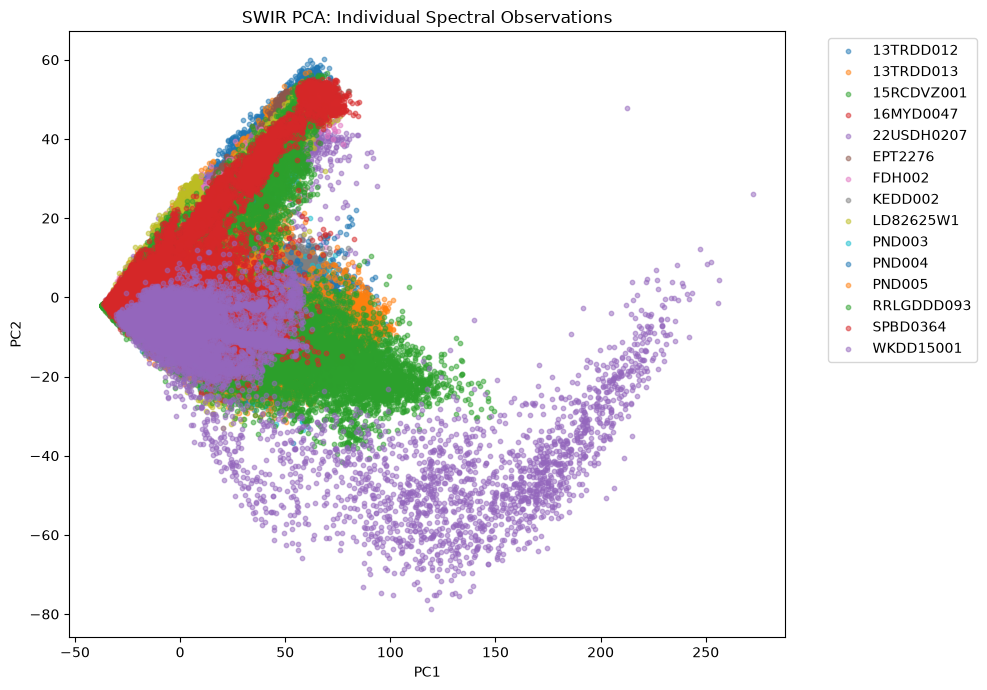

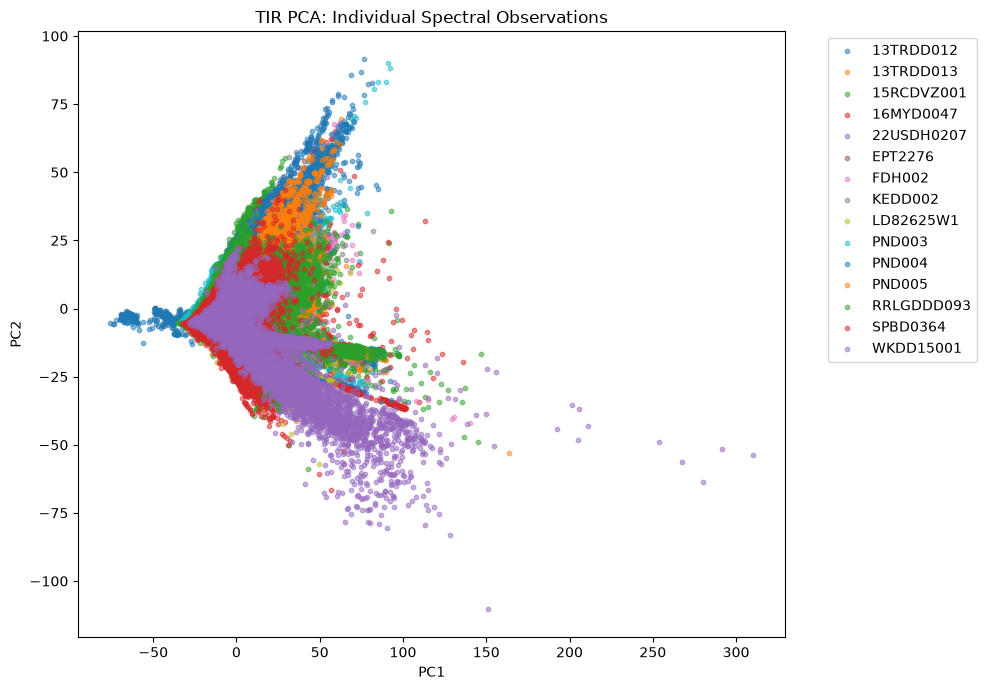

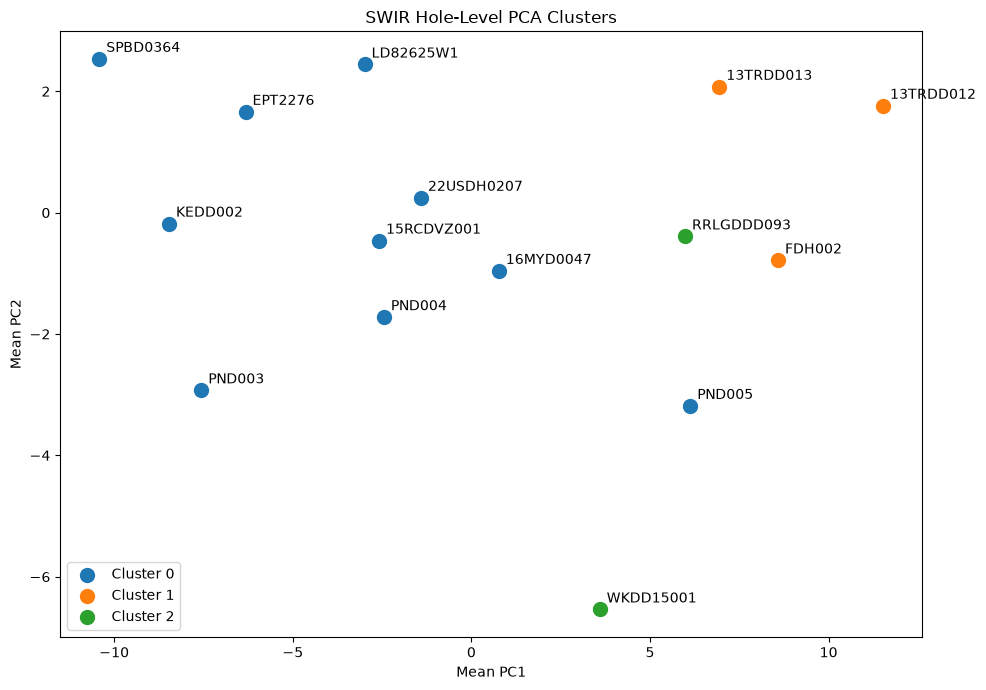

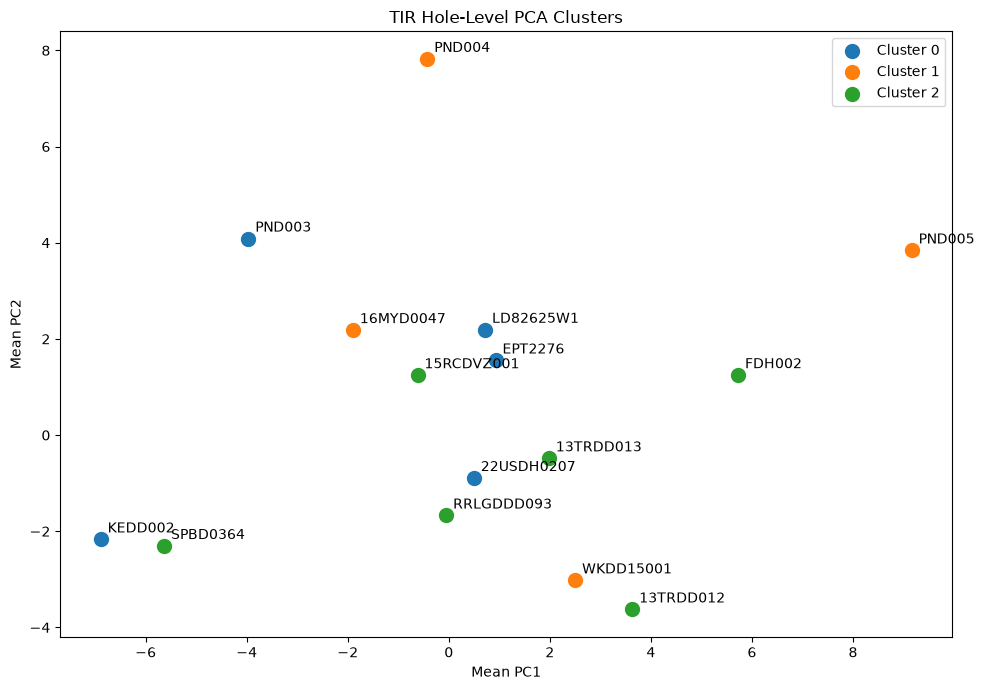




FINAL RESULTS

SWIR
Individual PCA observations: (1027111, 14)
Hole-level PCA representation: (15, 8)
Number of SWIR clusters: 3


   hole_id  SWIR_cluster  n_spectra
15RCDVZ001             0      61881
 16MYD0047             0      84420
22USDH0207             0      87071
   EPT2276             0      59840
   KEDD002             0     135037
 LD82625W1             0      96560
    PND003             0      28578
    PND004             0      31450
    PND005             0      60939
  SPBD0364             0      63656
 13TRDD012             1     119662
 13TRDD013             1      47704
    FDH002             1      42940
RRLGDDD093             2      60801
 WKDD15001             2      46572

TIR
Individual PCA observations: (1027111, 16)
Hole-level PCA representation: (15, 12)
Number of TIR clusters: 3


   hole_id  TIR_cluster  n_spectra
22USDH0207            0      87071
   EPT2276            0      59840
   KEDD002            0     135037
 LD82625W1            0      96560



PCA ANALYSIS: SWIR

Original spectral matrix:
Rows    = 1027111
Columns = 531

Every row represents one individual spectral observation.

Spectral preprocessing:
    StandardScaler : NO
    Row normalization : NO
    Spectral averaging : NO
    Median aggregation : NO
    Depth aggregation : NO
    Input spectra remain untouched.

PCA will perform its normal internal centering.

Running full PCA...

PCA variance retention:
Requested variance : 99.00%
Number of PCs retained: 4
Actual variance retained: 99.0231%

PCA score matrix:
Rows    = 1027111
Columns = 4

First principal components:
PC1: 0.831921
PC2: 0.110809
PC3: 0.037582
PC4: 0.009918


PCA ANALYSIS: TIR

Original spectral matrix:
Rows    = 1027111
Columns = 341

Every row represents one individual spectral observation.

Spectral preprocessing:
    StandardScaler : NO
    Row normalization : NO
    Spectral averaging : NO
    Median aggregation : NO
    Depth aggregation : NO
    Input spectra remain untouched.

PCA will perfo

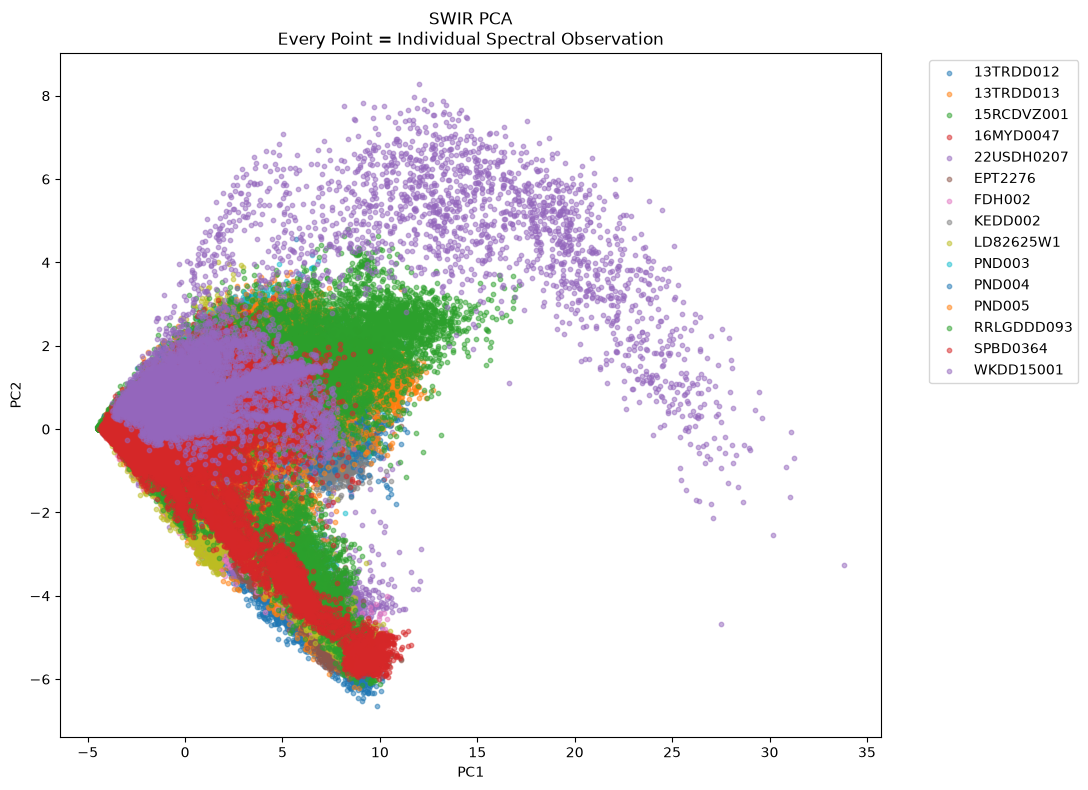

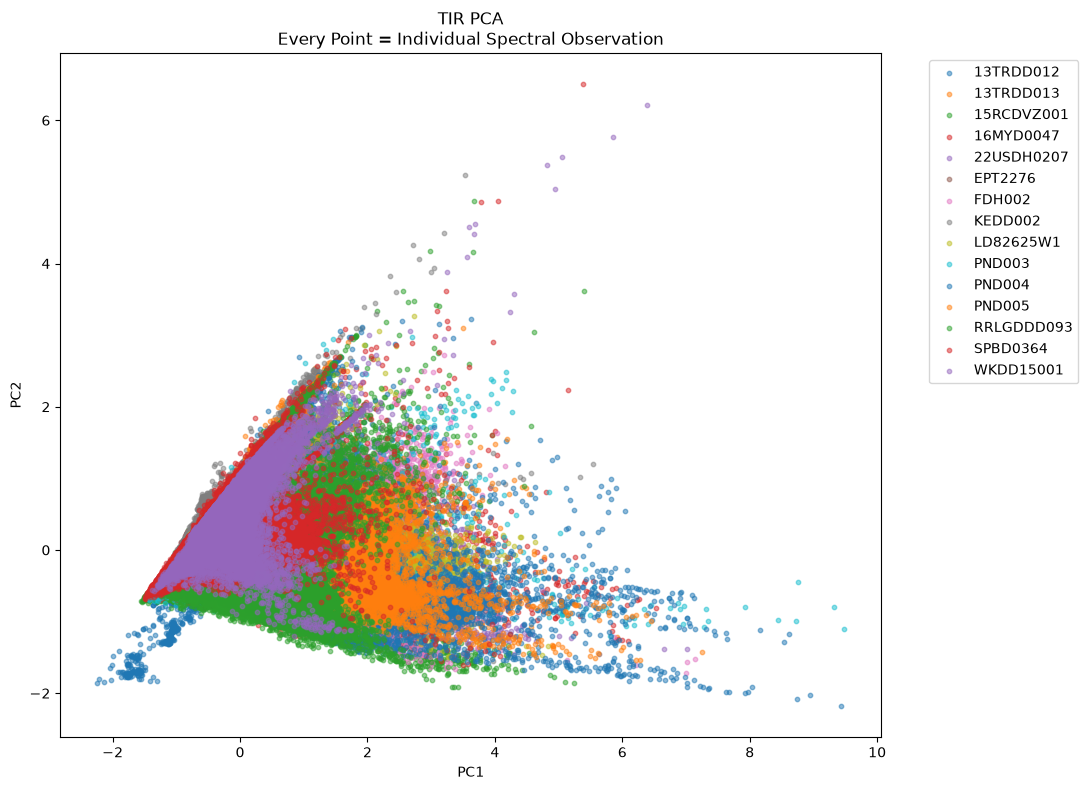

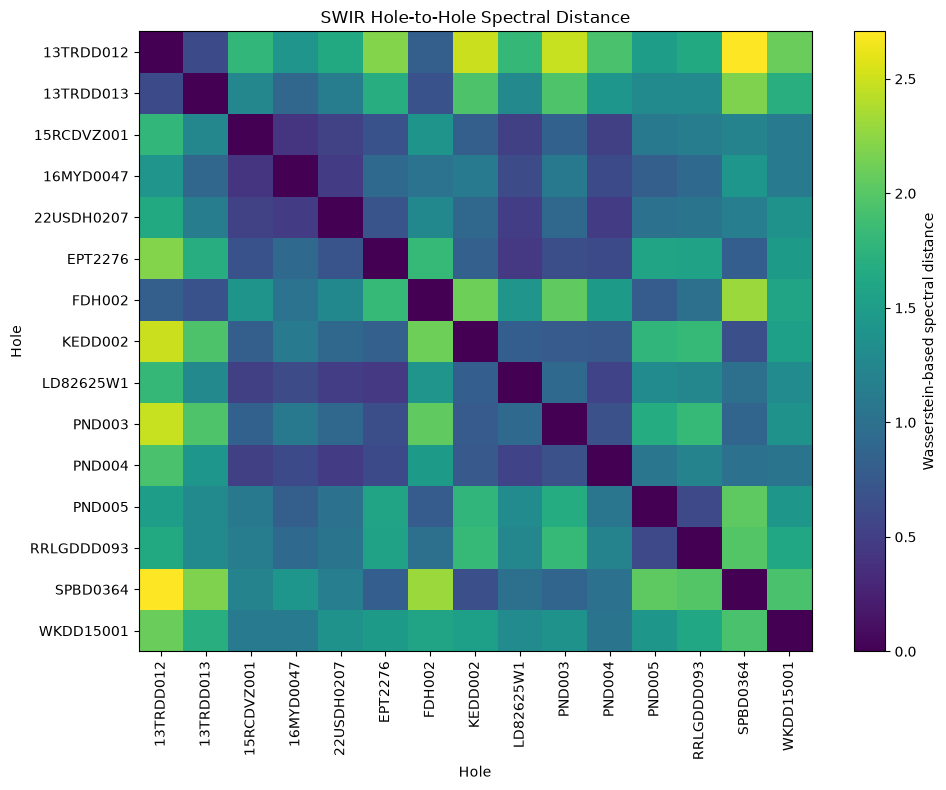

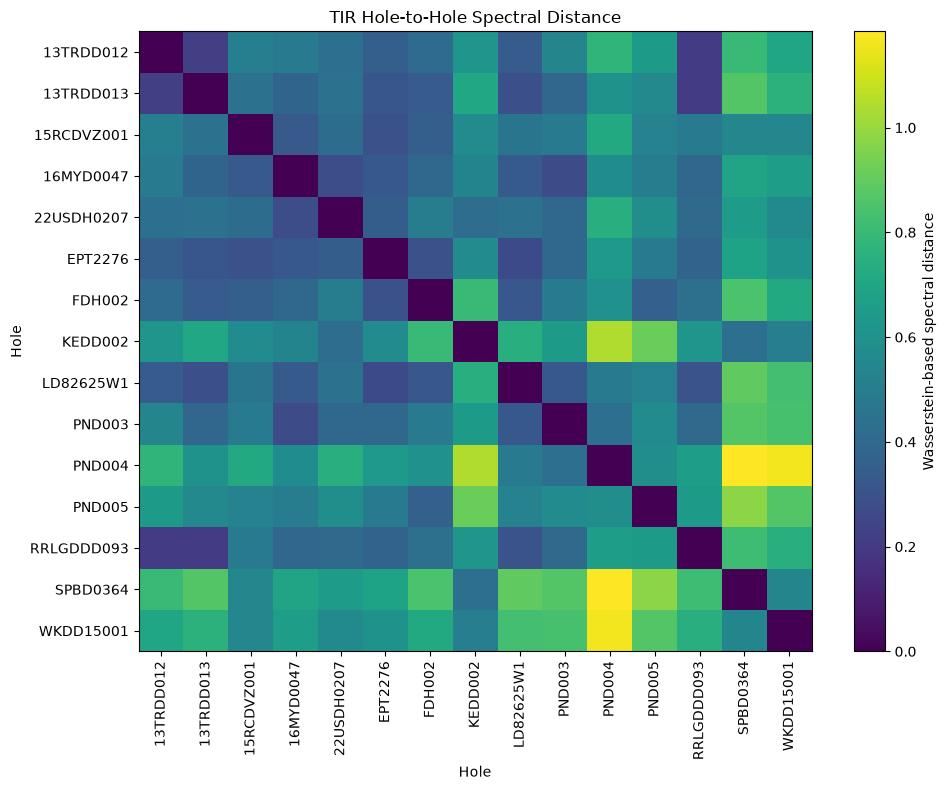




FINAL RESULTS

SWIR
------------------------------------------------------------------------------------------
Original spectral matrix: (1027111, 531)
Individual PCA observations: (1027111, 15)
Number of holes: 15
PCA components retained: 4
Variance retained: 100.0000%
Hole distance matrix: (15, 15)
Selected cluster count: 5
Silhouette score: 0.3180368371091445

SWIR hole clusters:
   hole_id  SWIR_cluster
   KEDD002             0
    PND003             0
  SPBD0364             0
 13TRDD012             1
 13TRDD013             1
    FDH002             1
 WKDD15001             2
    PND005             3
RRLGDDD093             3
15RCDVZ001             4
 16MYD0047             4
22USDH0207             4
   EPT2276             4
 LD82625W1             4
    PND004             4

TIR
------------------------------------------------------------------------------------------
Original spectral matrix: (1027111, 341)
Individual PCA observations: (1027111, 20)
Number of holes: 15
PCA compone

In [ ]:
# ============================================================
# PCA + HOLE-LEVEL SPECTRAL CLUSTERING
#
# SWIR and TIR are processed separately.
#
# SCIENTIFIC DESIGN
# ------------------------------------------------------------
#
# Each row of X_SWIR / X_TIR is one individual spectral
# observation.
#
# We DO NOT:
#
#   - average spectra
#   - calculate a mean spectrum per hole
#   - calculate a median spectrum per hole
#   - aggregate by depth bin
#   - normalize individual spectra
#   - StandardScaler the spectra
#   - create one artificial spectrum per hole
#
# PCA:
#
#   Individual spectra
#          |
#          v
#       PCA
#          |
#          v
#   Individual PC scores
#
# Hole comparison:
#
#   Hole A -> ALL individual PC observations
#   Hole B -> ALL individual PC observations
#   Hole C -> ALL individual PC observations
#              ...
#
# The distribution of individual PC scores belonging to each
# hole is compared using Wasserstein distance.
#
# The resulting hole-to-hole distance matrix is clustered
# using Agglomerative Clustering.
#
# ============================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.stats import wasserstein_distance


# ============================================================
# 1. SETTINGS
# ============================================================

# ------------------------------------------------------------
# PCA variance retention
#
# 0.99 means retain enough PCs to explain 99% of the total
# variance in the complete spectral dataset.
#
# We use 99% rather than 95% because the spectral information
# is delicate and we do not want to discard 5% unnecessarily.
# ------------------------------------------------------------

PCA_VARIANCE = 0.99


# ------------------------------------------------------------
# Initial number of clusters
#
# This is NOT assumed to be scientifically correct.
#
# We will evaluate several values of k later.
# ------------------------------------------------------------

N_CLUSTERS_SWIR = 10
N_CLUSTERS_TIR = 10


# ------------------------------------------------------------
# Range of k values for silhouette analysis
# ------------------------------------------------------------

MIN_K = 2
MAX_K = 30


# ============================================================
# 2. PCA FUNCTION
# ============================================================

def perform_pca(
    X,
    metadata,
    wavelengths,
    sensor_name,
    variance_threshold=0.99
):

    print("\n")
    print("=" * 90)
    print(f"PCA ANALYSIS: {sensor_name}")
    print("=" * 90)

    # ========================================================
    # 2.1 INPUT VALIDATION
    # ========================================================

    X = np.asarray(
        X,
        dtype=np.float64
    )

    if X.ndim != 2:

        raise ValueError(
            f"{sensor_name}: X must be a 2D matrix."
        )


    if len(X) != len(metadata):

        raise ValueError(
            f"{sensor_name}: number of spectra "
            f"does not match metadata rows."
        )


    if X.shape[1] != len(wavelengths):

        raise ValueError(
            f"{sensor_name}: number of spectral variables "
            f"does not match wavelength count."
        )


    if not np.isfinite(X).all():

        raise ValueError(
            f"{sensor_name}: non-finite spectral values detected."
        )


    # ========================================================
    # 2.2 ORIGINAL DATA INFORMATION
    # ========================================================

    print("\nOriginal spectral matrix:")
    print("Rows    =", X.shape[0])
    print("Columns =", X.shape[1])


    print(
        "\nEvery row represents one individual spectral observation."
    )


    # ========================================================
    # 2.3 IMPORTANT NOTE ABOUT PCA
    # ========================================================
    #
    # We DO NOT use:
    #
    #     StandardScaler()
    #
    # We DO NOT use:
    #
    #     row-wise normalization
    #
    # We DO NOT use:
    #
    #     vector normalization
    #
    # PCA itself centers each wavelength variable internally.
    #
    # This means:
    #
    #     X
    #      |
    #      v
    #     PCA
    #
    # rather than:
    #
    #     X
    #      |
    #      v
    # StandardScaler
    #      |
    #      v
    #     PCA
    #
    # ========================================================

    print("\nSpectral preprocessing:")
    print("    StandardScaler : NO")
    print("    Row normalization : NO")
    print("    Spectral averaging : NO")
    print("    Median aggregation : NO")
    print("    Depth aggregation : NO")
    print("    Input spectra remain untouched.")
    print("\nPCA will perform its normal internal centering.")


    # ========================================================
    # 2.4 FULL PCA
    # ========================================================

    print("\nRunning full PCA...")

    pca_full = PCA()

    X_pca_full = pca_full.fit_transform(X)


    # ========================================================
    # 2.5 EXPLAINED VARIANCE
    # ========================================================

    explained_variance = (
        pca_full.explained_variance_ratio_
    )


    cumulative_variance = np.cumsum(
        explained_variance
    )


    # ========================================================
    # 2.6 DETERMINE NUMBER OF COMPONENTS
    # ========================================================

    n_components = (

        np.searchsorted(
            cumulative_variance,
            variance_threshold
        )

        + 1

    )


    n_components = min(
        n_components,
        X_pca_full.shape[1]
    )


    print("\nPCA variance retention:")
    print(
        f"Requested variance : "
        f"{variance_threshold:.2%}"
    )

    print(
        "Number of PCs retained:",
        n_components
    )

    print(
        "Actual variance retained:",
        f"{cumulative_variance[n_components - 1]:.4%}"
    )


    # ========================================================
    # 2.7 FINAL PCA
    # ========================================================

    pca = PCA(
        n_components=n_components
    )


    X_pca = pca.fit_transform(X)


    # ========================================================
    # 2.8 PCA COLUMN NAMES
    # ========================================================

    pc_columns = [

        f"PC{i + 1}"

        for i in range(n_components)

    ]


    pca_scores = pd.DataFrame(

        X_pca,

        columns=pc_columns

    )


    # ========================================================
    # 2.9 ATTACH ORIGINAL METADATA
    # ========================================================
    #
    # IMPORTANT:
    #
    # Row i still corresponds to the exact same original
    # spectral observation.
    #
    # No observations are combined.
    #
    # ========================================================

    pca_data = pd.concat(

        [

            metadata.reset_index(drop=True),

            pca_scores

        ],

        axis=1

    )


    # ========================================================
    # 2.10 VERIFY ROW ALIGNMENT
    # ========================================================

    if len(pca_data) != len(X):

        raise ValueError(
            f"{sensor_name}: PCA row alignment failed."
        )


    # ========================================================
    # 2.11 PRINT PCA INFORMATION
    # ========================================================

    print("\nPCA score matrix:")
    print(
        "Rows    =",
        X_pca.shape[0]
    )

    print(
        "Columns =",
        X_pca.shape[1]
    )


    print("\nFirst principal components:")

    for i in range(
        min(5, n_components)
    ):

        print(
            f"PC{i + 1}: "
            f"{explained_variance[i]:.6f}"
        )


    # ========================================================
    # 2.12 RETURN
    # ========================================================

    return {

        "pca": pca,

        "pca_data": pca_data,

        "pca_scores": X_pca,

        "explained_variance":
            explained_variance,

        "cumulative_variance":
            cumulative_variance,

        "n_components":
            n_components

    }


# ============================================================
# 3. RUN PCA ON SWIR
# ============================================================

swir_pca_result = perform_pca(

    X_SWIR,

    SWIR_METADATA,

    SWIR_WAVELENGTHS,

    "SWIR",

    PCA_VARIANCE

)


SWIR_PCA_MODEL = (
    swir_pca_result["pca"]
)


SWIR_PCA_DATA = (
    swir_pca_result["pca_data"]
)


SWIR_PCA_SCORES = (
    swir_pca_result["pca_scores"]
)


# ============================================================
# 4. RUN PCA ON TIR
# ============================================================

tir_pca_result = perform_pca(

    X_TIR,

    TIR_METADATA,

    TIR_WAVELENGTHS,

    "TIR",

    PCA_VARIANCE

)


TIR_PCA_MODEL = (
    tir_pca_result["pca"]
)


TIR_PCA_DATA = (
    tir_pca_result["pca_data"]
)


TIR_PCA_SCORES = (
    tir_pca_result["pca_scores"]
)


# ============================================================
# 5. PCA VARIANCE TABLE
# ============================================================

def create_variance_table(
    pca_result,
    sensor_name
):

    n = pca_result["n_components"]

    variance = (
        pca_result[
            "explained_variance"
        ][:n]
    )

    cumulative = (
        pca_result[
            "cumulative_variance"
        ][:n]
    )


    table = pd.DataFrame({

        "Component": [

            f"PC{i + 1}"

            for i in range(n)

        ],

        "Explained_Variance":
            variance,

        "Cumulative_Variance":
            cumulative

    })


    print("\n")
    print("=" * 90)
    print(
        f"{sensor_name} PCA VARIANCE TABLE"
    )
    print("=" * 90)

    print(
        table.to_string(
            index=False
        )
    )


    return table


SWIR_VARIANCE_TABLE = (
    create_variance_table(
        swir_pca_result,
        "SWIR"
    )
)


TIR_VARIANCE_TABLE = (
    create_variance_table(
        tir_pca_result,
        "TIR"
    )
)


# ============================================================
# 6. VERIFY INDIVIDUAL PCA OBSERVATIONS
# ============================================================

print("\n")
print("=" * 90)
print("INDIVIDUAL PCA OBSERVATIONS")
print("=" * 90)


print("\nSWIR:")

display_columns = [
    "hole_id",
    "depth_m",
    "depth_bin",
    "PC1"
]

if "PC2" in SWIR_PCA_DATA.columns:

    display_columns.append("PC2")


print(
    SWIR_PCA_DATA[
        display_columns
    ].head(10)
)


print("\nTIR:")

display_columns = [
    "hole_id",
    "depth_m",
    "depth_bin",
    "PC1"
]

if "PC2" in TIR_PCA_DATA.columns:

    display_columns.append("PC2")


print(
    TIR_PCA_DATA[
        display_columns
    ].head(10)
)


# ============================================================
# 7. CHECK NUMBER OF SPECTRA PER HOLE
# ============================================================

def print_hole_observation_counts(
    pca_data,
    sensor_name
):

    counts = (

        pca_data

        .groupby("hole_id")

        .size()

        .sort_index()

    )


    print("\n")
    print("=" * 90)
    print(
        f"{sensor_name} INDIVIDUAL SPECTRA PER HOLE"
    )
    print("=" * 90)


    print(counts)


    print(
        "\nNumber of holes:",
        len(counts)
    )


    print(
        "Total individual observations:",
        counts.sum()
    )


    return counts


SWIR_HOLE_COUNTS = (
    print_hole_observation_counts(
        SWIR_PCA_DATA,
        "SWIR"
    )
)


TIR_HOLE_COUNTS = (
    print_hole_observation_counts(
        TIR_PCA_DATA,
        "TIR"
    )
)


# ============================================================
# 8. SELECT PCs FOR HOLE COMPARISON
# ============================================================
#
# We use ALL PCs retained by the variance threshold.
#
# There is NO arbitrary:
#
#     MAX_DISTANCE_PCS = 10
#
# because that could discard useful spectral information.
#
# ============================================================

def select_pca_components(
    pca_data
):

    pc_columns = [

        column

        for column in pca_data.columns

        if column.startswith("PC")

    ]


    if len(pc_columns) == 0:

        raise ValueError(
            "No PCA components found."
        )


    return pc_columns


SWIR_DISTANCE_PCS = (
    select_pca_components(
        SWIR_PCA_DATA
    )
)


TIR_DISTANCE_PCS = (
    select_pca_components(
        TIR_PCA_DATA
    )
)


print("\n")
print("=" * 90)
print("PCA COMPONENTS USED FOR HOLE COMPARISON")
print("=" * 90)


print(
    "SWIR:",
    len(SWIR_DISTANCE_PCS),
    "components"
)


print(
    "TIR:",
    len(TIR_DISTANCE_PCS),
    "components"
)


# ============================================================
# 9. CALCULATE HOLE-TO-HOLE SPECTRAL DISTANCES
# ============================================================
#
# THIS IS THE IMPORTANT PART.
#
# We never create:
#
#     mean spectrum
#     median spectrum
#     mean PC vector
#
# for a hole.
#
# Instead:
#
# Hole A:
#
#     PC1 = [all individual PC1 observations]
#     PC2 = [all individual PC2 observations]
#     ...
#
# Hole B:
#
#     PC1 = [all individual PC1 observations]
#     PC2 = [all individual PC2 observations]
#     ...
#
# The distributions are compared directly.
#
# Wasserstein distance measures the amount of "work" required
# to transform one empirical distribution into another.
#
# ============================================================

def calculate_hole_distance_matrix(
    pca_data,
    pc_columns,
    sensor_name
):

    print("\n")
    print("=" * 90)
    print(
        f"HOLE-TO-HOLE SPECTRAL DISTANCE: "
        f"{sensor_name}"
    )
    print("=" * 90)


    # --------------------------------------------------------
    # Hole list
    # --------------------------------------------------------

    holes = sorted(

        pca_data[
            "hole_id"
        ]

        .dropna()

        .unique()

    )


    n_holes = len(holes)


    print(
        "\nNumber of holes:",
        n_holes
    )


    print(
        "Number of PCA dimensions:",
        len(pc_columns)
    )


    # --------------------------------------------------------
    # Pre-store observations
    #
    # Every observation remains separate.
    # --------------------------------------------------------

    hole_pc_values = {}


    for hole_id in holes:

        hole_rows = (
            pca_data[
                pca_data["hole_id"] == hole_id
            ]
        )


        hole_pc_values[hole_id] = {}


        for pc in pc_columns:

            values = (

                hole_rows[pc]

                .to_numpy(
                    dtype=np.float64
                )

            )


            if len(values) == 0:

                raise ValueError(
                    f"{sensor_name}: "
                    f"hole {hole_id} has no "
                    f"observations for {pc}."
                )


            if not np.isfinite(values).all():

                raise ValueError(
                    f"{sensor_name}: "
                    f"non-finite PC values in "
                    f"hole {hole_id}."
                )


            hole_pc_values[
                hole_id
            ][pc] = values


    # --------------------------------------------------------
    # Distance matrix
    # --------------------------------------------------------

    distance_matrix = np.zeros(

        (
            n_holes,
            n_holes
        ),

        dtype=np.float64

    )


    # --------------------------------------------------------
    # Pairwise hole distances
    # --------------------------------------------------------

    for i in range(n_holes):

        hole_i = holes[i]


        for j in range(
            i + 1,
            n_holes
        ):

            hole_j = holes[j]


            pc_distances = []


            # ------------------------------------------------
            # Compare distributions for every PC
            # ------------------------------------------------

            for pc in pc_columns:

                values_i = (
                    hole_pc_values[
                        hole_i
                    ][pc]
                )


                values_j = (
                    hole_pc_values[
                        hole_j
                    ][pc]
                )


                distance = (

                    wasserstein_distance(

                        values_i,

                        values_j

                    )

                )


                pc_distances.append(
                    distance
                )


            # ------------------------------------------------
            # Combine PC distances
            #
            # We do NOT standardize these distances.
            #
            # PC1, PC2, ... retain their natural PCA scale.
            #
            # Euclidean combination across PC-wise Wasserstein
            # distances is used.
            # ------------------------------------------------

            pc_distances = np.asarray(
                pc_distances,
                dtype=np.float64
            )


            combined_distance = np.sqrt(

                np.sum(
                    pc_distances ** 2
                )

            )


            distance_matrix[i, j] = (
                combined_distance
            )


            distance_matrix[j, i] = (
                combined_distance
            )


    distance_df = pd.DataFrame(

        distance_matrix,

        index=holes,

        columns=holes

    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    if not np.isfinite(
        distance_matrix
    ).all():

        raise ValueError(
            f"{sensor_name}: "
            "non-finite distances detected."
        )


    if not np.allclose(
        distance_matrix,
        distance_matrix.T
    ):

        raise ValueError(
            f"{sensor_name}: "
            "distance matrix is not symmetric."
        )


    if not np.allclose(
        np.diag(distance_matrix),
        0
    ):

        raise ValueError(
            f"{sensor_name}: "
            "distance matrix diagonal is not zero."
        )


    print(
        "\nDistance matrix shape:",
        distance_df.shape
    )


    return (
        distance_df,
        holes
    )


# ============================================================
# 10. SWIR HOLE DISTANCE MATRIX
# ============================================================

(
    SWIR_HOLE_DISTANCE_MATRIX,
    SWIR_HOLES
) = calculate_hole_distance_matrix(

    SWIR_PCA_DATA,

    SWIR_DISTANCE_PCS,

    "SWIR"

)


# ============================================================
# 11. TIR HOLE DISTANCE MATRIX
# ============================================================

(
    TIR_HOLE_DISTANCE_MATRIX,
    TIR_HOLES
) = calculate_hole_distance_matrix(

    TIR_PCA_DATA,

    TIR_DISTANCE_PCS,

    "TIR"

)


# ============================================================
# 12. PRINT DISTANCE MATRICES
# ============================================================

print("\n")
print("=" * 90)
print("SWIR HOLE-TO-HOLE DISTANCE MATRIX")
print("=" * 90)

print(
    SWIR_HOLE_DISTANCE_MATRIX
)


print("\n")
print("=" * 90)
print("TIR HOLE-TO-HOLE DISTANCE MATRIX")
print("=" * 90)

print(
    TIR_HOLE_DISTANCE_MATRIX
)


# ============================================================
# 13. CLUSTER HOLES
# ============================================================
#
# We cluster the HOLES.
#
# We do NOT cluster individual spectra.
#
# The input is:
#
#     hole-to-hole distance matrix
#
# ============================================================

def cluster_holes_from_distance(

    distance_df,

    sensor_name,

    n_clusters

):

    print("\n")
    print("=" * 90)
    print(
        f"CLUSTERING HOLES: {sensor_name}"
    )
    print("=" * 90)


    holes = (
        distance_df.index.to_list()
    )


    distance_matrix = (
        distance_df.to_numpy(
            dtype=np.float64
        )
    )


    # ========================================================
    # VALIDATION
    # ========================================================

    if n_clusters < 2:

        raise ValueError(
            "Number of clusters must be >= 2."
        )


    if n_clusters >= len(holes):

        raise ValueError(
            "Number of clusters must be "
            "smaller than number of holes."
        )


    # ========================================================
    # AGGLOMERATIVE CLUSTERING
    # ========================================================

    model = AgglomerativeClustering(

        n_clusters=n_clusters,

        metric="precomputed",

        linkage="average"

    )


    labels = model.fit_predict(
        distance_matrix
    )


    # ========================================================
    # RESULT
    # ========================================================

    result = pd.DataFrame({

        "hole_id":
            holes,

        f"{sensor_name}_cluster":
            labels

    })


    # ========================================================
    # PRINT
    # ========================================================

    print("\nHole cluster assignments:")


    print(

        result

        .sort_values(
            f"{sensor_name}_cluster"
        )

        .to_string(
            index=False
        )

    )


    print("\nCluster sizes:")


    print(

        result[
            f"{sensor_name}_cluster"
        ]

        .value_counts()

        .sort_index()

    )


    return (
        result,
        model
    )


# ============================================================
# 14. SWIR CLUSTERING
# ============================================================

(
    SWIR_HOLE_CLUSTERS,
    SWIR_CLUSTER_MODEL
) = cluster_holes_from_distance(

    SWIR_HOLE_DISTANCE_MATRIX,

    "SWIR",

    N_CLUSTERS_SWIR

)


# ============================================================
# 15. TIR CLUSTERING
# ============================================================

(
    TIR_HOLE_CLUSTERS,
    TIR_CLUSTER_MODEL
) = cluster_holes_from_distance(

    TIR_HOLE_DISTANCE_MATRIX,

    "TIR",

    N_CLUSTERS_TIR

)


# ============================================================
# 16. SILHOUETTE SCORE
# ============================================================

def calculate_silhouette(

    distance_matrix,

    labels,

    sensor_name

):

    unique_labels = np.unique(
        labels
    )


    if len(unique_labels) < 2:

        return np.nan


    if len(unique_labels) >= len(labels):

        return np.nan


    score = silhouette_score(

        distance_matrix,

        labels,

        metric="precomputed"

    )


    print(
        f"{sensor_name} silhouette score:",
        score
    )


    return score


SWIR_SILHOUETTE = (
    calculate_silhouette(

        SWIR_HOLE_DISTANCE_MATRIX.to_numpy(),

        SWIR_HOLE_CLUSTERS[
            "SWIR_cluster"
        ].to_numpy(),

        "SWIR"

    )
)


TIR_SILHOUETTE = (
    calculate_silhouette(

        TIR_HOLE_DISTANCE_MATRIX.to_numpy(),

        TIR_HOLE_CLUSTERS[
            "TIR_cluster"
        ].to_numpy(),

        "TIR"

    )
)


# ============================================================
# 17. TEST DIFFERENT NUMBERS OF CLUSTERS
#
# This is preferable to assuming k = 3.
# ============================================================

def evaluate_cluster_counts(

    distance_df,

    sensor_name,

    min_k=2,

    max_k=8

):

    distance_matrix = (
        distance_df.to_numpy()
    )


    n_holes = len(distance_df)


    max_allowed_k = min(
        max_k,
        n_holes - 1
    )


    results = []


    print("\n")
    print("=" * 90)
    print(
        f"{sensor_name} CLUSTER COUNT EVALUATION"
    )
    print("=" * 90)


    for k in range(
        min_k,
        max_allowed_k + 1
    ):

        model = AgglomerativeClustering(

            n_clusters=k,

            metric="precomputed",

            linkage="average"

        )


        labels = model.fit_predict(
            distance_matrix
        )


        score = silhouette_score(

            distance_matrix,

            labels,

            metric="precomputed"

        )


        results.append({

            "n_clusters": k,

            "silhouette_score": score

        })


    results_df = pd.DataFrame(
        results
    )


    print(
        results_df.to_string(
            index=False
        )
    )


    return results_df


SWIR_CLUSTER_EVALUATION = (
    evaluate_cluster_counts(

        SWIR_HOLE_DISTANCE_MATRIX,

        "SWIR",

        MIN_K,

        MAX_K

    )
)


TIR_CLUSTER_EVALUATION = (
    evaluate_cluster_counts(

        TIR_HOLE_DISTANCE_MATRIX,

        "TIR",

        MIN_K,

        MAX_K

    )
)


# ============================================================
# 18. PLOT INDIVIDUAL PCA OBSERVATIONS
#
# IMPORTANT:
#
# Every point is one individual spectrum.
#
# There is NO hole averaging in this plot.
# ============================================================

def plot_individual_pca(

    pca_data,

    sensor_name

):

    if not (

        "PC1" in pca_data.columns

        and

        "PC2" in pca_data.columns

    ):

        print(
            f"{sensor_name}: "
            "PC1 and PC2 unavailable."
        )

        return


    plt.figure(
        figsize=(11, 8)
    )


    for hole_id, group in (

        pca_data

        .groupby("hole_id")

    ):

        plt.scatter(

            group["PC1"],

            group["PC2"],

            s=10,

            alpha=0.5,

            label=str(hole_id)

        )


    plt.xlabel(
        "PC1"
    )


    plt.ylabel(
        "PC2"
    )


    plt.title(

        f"{sensor_name} PCA\n"
        "Every Point = Individual Spectral Observation"

    )


    if pca_data[
        "hole_id"
    ].nunique() <= 20:

        plt.legend(

            bbox_to_anchor=(1.05, 1),

            loc="upper left"

        )


    plt.tight_layout()

    plt.show()


# ============================================================
# 19. SWIR PCA PLOT
# ============================================================

plot_individual_pca(

    SWIR_PCA_DATA,

    "SWIR"

)


# ============================================================
# 20. TIR PCA PLOT
# ============================================================

plot_individual_pca(

    TIR_PCA_DATA,

    "TIR"

)


# ============================================================
# 21. DISTANCE MATRIX HEATMAP
# ============================================================

def plot_distance_matrix(

    distance_df,

    sensor_name

):

    plt.figure(

        figsize=(10, 8)

    )


    plt.imshow(

        distance_df.to_numpy(),

        aspect="auto"

    )


    plt.colorbar(

        label="Wasserstein-based spectral distance"

    )


    plt.xticks(

        range(len(distance_df)),

        distance_df.columns,

        rotation=90

    )


    plt.yticks(

        range(len(distance_df)),

        distance_df.index

    )


    plt.xlabel(
        "Hole"
    )


    plt.ylabel(
        "Hole"
    )


    plt.title(

        f"{sensor_name} "
        "Hole-to-Hole Spectral Distance"

    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 22. SWIR DISTANCE HEATMAP
# ============================================================

plot_distance_matrix(

    SWIR_HOLE_DISTANCE_MATRIX,

    "SWIR"

)


# ============================================================
# 23. TIR DISTANCE HEATMAP
# ============================================================

plot_distance_matrix(

    TIR_HOLE_DISTANCE_MATRIX,

    "TIR"

)


# ============================================================
# 24. FINAL RESULTS
# ============================================================

print("\n\n")
print("=" * 90)
print("FINAL RESULTS")
print("=" * 90)


# ------------------------------------------------------------
# SWIR
# ------------------------------------------------------------

print("\nSWIR")
print("-" * 90)


print(
    "Original spectral matrix:",
    X_SWIR.shape
)


print(
    "Individual PCA observations:",
    SWIR_PCA_DATA.shape
)


print(
    "Number of holes:",
    len(SWIR_HOLES)
)


print(
    "PCA components retained:",
    len(SWIR_DISTANCE_PCS)
)


print(
    "Variance retained:",
    f"{swir_pca_result['cumulative_variance'][-1]:.4%}"
)


print(
    "Hole distance matrix:",
    SWIR_HOLE_DISTANCE_MATRIX.shape
)


print(
    "Selected cluster count:",
    N_CLUSTERS_SWIR
)


print(
    "Silhouette score:",
    SWIR_SILHOUETTE
)


print("\nSWIR hole clusters:")


print(

    SWIR_HOLE_CLUSTERS

    .sort_values(
        "SWIR_cluster"
    )

    .to_string(
        index=False
    )

)


# ------------------------------------------------------------
# TIR
# ------------------------------------------------------------

print("\nTIR")
print("-" * 90)


print(
    "Original spectral matrix:",
    X_TIR.shape
)


print(
    "Individual PCA observations:",
    TIR_PCA_DATA.shape
)


print(
    "Number of holes:",
    len(TIR_HOLES)
)


print(
    "PCA components retained:",
    len(TIR_DISTANCE_PCS)
)


print(
    "Variance retained:",
    f"{tir_pca_result['cumulative_variance'][-1]:.4%}"
)


print(
    "Hole distance matrix:",
    TIR_HOLE_DISTANCE_MATRIX.shape
)


print(
    "Selected cluster count:",
    N_CLUSTERS_TIR
)


print(
    "Silhouette score:",
    TIR_SILHOUETTE
)


print("\nTIR hole clusters:")


print(

    TIR_HOLE_CLUSTERS

    .sort_values(
        "TIR_cluster"
    )

    .to_string(
        index=False
    )

)


# ============================================================
# 25. IMPORTANT OUTPUT OBJECTS
# ============================================================

print("\n")
print("=" * 90)
print("IMPORTANT OUTPUT OBJECTS")
print("=" * 90)


print(
    """
ORIGINAL SPECTRAL MATRICES
--------------------------

X_SWIR
X_TIR


ORIGINAL METADATA
-----------------

SWIR_METADATA
TIR_METADATA


PCA RESULTS
-----------

SWIR_PCA_DATA
TIR_PCA_DATA

SWIR_PCA_SCORES
TIR_PCA_SCORES

SWIR_PCA_MODEL
TIR_PCA_MODEL


PCA VARIANCE
------------

SWIR_VARIANCE_TABLE
TIR_VARIANCE_TABLE


HOLE-TO-HOLE SPECTRAL DISTANCES
-------------------------------

SWIR_HOLE_DISTANCE_MATRIX
TIR_HOLE_DISTANCE_MATRIX


HOLE CLUSTERS
-------------

SWIR_HOLE_CLUSTERS
TIR_HOLE_CLUSTERS


CLUSTERING MODELS
-----------------

SWIR_CLUSTER_MODEL
TIR_CLUSTER_MODEL


CLUSTER COUNT EVALUATION
------------------------

SWIR_CLUSTER_EVALUATION
TIR_CLUSTER_EVALUATION
"""
)


# ============================================================
# 26. FINAL SCIENTIFIC CHECK
# ============================================================

print("\n")
print("=" * 90)
print("DATA INTEGRITY CHECK")
print("=" * 90)


print(
    "SWIR original observations:",
    X_SWIR.shape[0]
)


print(
    "SWIR PCA observations:",
    SWIR_PCA_DATA.shape[0]
)


print(
    "TIR original observations:",
    X_TIR.shape[0]
)


print(
    "TIR PCA observations:",
    TIR_PCA_DATA.shape[0]
)


assert (
    X_SWIR.shape[0]
    ==
    SWIR_PCA_DATA.shape[0]
)


assert (
    X_TIR.shape[0]
    ==
    TIR_PCA_DATA.shape[0]
)


print("\nPASS:")
print(
    "Every SWIR spectral observation "
    "has a corresponding PCA observation."
)


print("PASS:")
print(
    "Every TIR spectral observation "
    "has a corresponding PCA observation."
)


print("PASS:")
print(
    "No hole-level mean spectrum was created."
)


print("PASS:")
print(
    "No hole-level median spectrum was created."
)


print("PASS:")
print(
    "No depth-bin spectral aggregation was performed."
)


print("PASS:")
print(
    "No StandardScaler was applied to the spectral matrix."
)


print("PASS:")
print(
    "No row-wise spectral normalization was performed."
)


print("\n")
print("=" * 90)
print("PCA + HOLE-LEVEL SPECTRAL CLUSTERING COMPLETE")
print("=" * 90)